1. Test the environment

In [8]:

import sys

print("Jupyter is working!")
print("Python executable:", sys.executable)


Jupyter is working!
Python executable: c:\GroupWork\DS_research_project-maria_kisakye-\.venv\Scripts\python.exe


2. Import libraries and locate the datasets

In [9]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Find the project folder, regardless of notebook working directory
current = Path.cwd().resolve()

if (current / "data" / "raw").exists():
    PROJECT_ROOT = current
elif (current.parent / "data" / "raw").exists():
    PROJECT_ROOT = current.parent
else:
    raise FileNotFoundError(
        f"Cannot find data/raw from {current}. "
        "Open the research project folder in VS Code."
    )

DATA_DIR = PROJECT_ROOT / "data" / "raw"

print("Project folder:", PROJECT_ROOT)
print("Data folder:", DATA_DIR)


Project folder: C:\GroupWork\DS_research_project-maria_kisakye-
Data folder: C:\GroupWork\DS_research_project-maria_kisakye-\data\raw


3. Load the three datasets

In [10]:

performance = pd.read_csv(DATA_DIR / "trainperf.csv")
demographics = pd.read_csv(DATA_DIR / "traindemographics.csv")
previous_loans = pd.read_csv(DATA_DIR / "trainprevloans.csv")

print("Performance:", performance.shape)
print("Demographics:", demographics.shape)
print("Previous loans:", previous_loans.shape)


Performance: (4368, 10)
Demographics: (4346, 9)
Previous loans: (18183, 12)


4. Inspect the dataset structure

In [11]:

for name, df in [
    ("Performance", performance),
    ("Demographics", demographics),
    ("Previous loans", previous_loans),
]:
    print(f"\n{name}")
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print("\nMissing values:")
    print(df.isna().sum())



Performance
Rows: 4368
Columns: ['customerid', 'systemloanid', 'loannumber', 'approveddate', 'creationdate', 'loanamount', 'totaldue', 'termdays', 'referredby', 'good_bad_flag']

Missing values:
customerid          0
systemloanid        0
loannumber          0
approveddate        0
creationdate        0
loanamount          0
totaldue            0
termdays            0
referredby       3781
good_bad_flag       0
dtype: int64

Demographics
Rows: 4346
Columns: ['customerid', 'birthdate', 'bank_account_type', 'longitude_gps', 'latitude_gps', 'bank_name_clients', 'bank_branch_clients', 'employment_status_clients', 'level_of_education_clients']

Missing values:
customerid                       0
birthdate                        0
bank_account_type                0
longitude_gps                    0
latitude_gps                     0
bank_name_clients                0
bank_branch_clients           4295
employment_status_clients      648
level_of_education_clients    3759
dtype: int64

Previo

5. Examine loan outcomes

good_bad_flag
Good    3416
Bad      952
Name: count, dtype: int64


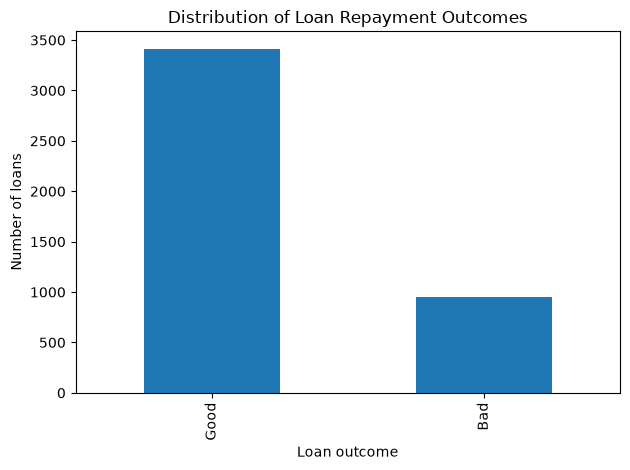

In [12]:

print(performance["good_bad_flag"].value_counts(dropna=False))

performance["good_bad_flag"].value_counts().plot(
    kind="bar",
    title="Distribution of Loan Repayment Outcomes"
)

plt.xlabel("Loan outcome")
plt.ylabel("Number of loans")
plt.tight_layout()
plt.show()


##### 6. Customer Identification and Data Integration Checks

Before combining the datasets, we examine unique customer identifiers, duplicate records, and customer coverage across the three datasets. This helps us select an appropriate merging strategy and preserve the integrity of the loan-performance records.

In [13]:

# Count unique customers
for name, df in [
    ("Performance", performance),
    ("Demographics", demographics),
    ("Previous loans", previous_loans)
]:
    print(f"{name}:")
    print("  Total records:", len(df))
    print("  Unique customers:", df["customerid"].nunique())
    print("  Duplicate customer IDs:",
          df["customerid"].duplicated().sum())
    print()

# Check customer coverage
target_customers = set(performance["customerid"])

demographic_customers = set(demographics["customerid"])
previous_customers = set(previous_loans["customerid"])

print("Performance customers missing demographics:",
      len(target_customers - demographic_customers))

print("Performance customers missing previous-loan history:",
      len(target_customers - previous_customers))

print("Customers appearing in all three datasets:",
      len(target_customers & demographic_customers & previous_customers))


Performance:
  Total records: 4368
  Unique customers: 4368
  Duplicate customer IDs: 0

Demographics:
  Total records: 4346
  Unique customers: 4334
  Duplicate customer IDs: 12

Previous loans:
  Total records: 18183
  Unique customers: 4359
  Duplicate customer IDs: 13824

Performance customers missing demographics: 1099
Performance customers missing previous-loan history: 9
Customers appearing in all three datasets: 3264


##### 6.1 Interpretation of Customer Identification and Data Integration Results

Before merging the three datasets, we examined the number of records, unique customers, duplicate customer IDs, and customer coverage across the datasets.

The loan performance dataset contains **4,368 records belonging to 4,368 unique customers**, meaning each customer appears only once. This dataset will serve as our main table because it contains the loan repayment outcomes (`good_bad_flag`) that we aim to predict.

The demographic dataset contains **4,346 records belonging to 4,334 unique customers**, indicating 12 additional records associated with repeated customer IDs. These records require further investigation before merging to avoid duplicating customers.

The previous-loan dataset contains **18,183 records belonging to 4,359 unique customers**. The repeated customer IDs are expected because customers may have taken several loans in the past. These historical records can provide useful information about borrowing behaviour.

**Customer coverage analysis** revealed that:

- 1,099 customers in the performance dataset have no matching demographic record.
- Only 9 customers have no matching previous-loan record.
- 3,264 customers appear in all three datasets.

These findings show that most customers have previous-loan information, but a significant number lack demographic records.

**Data integration decision:** We will use the loan performance dataset as the main table and apply left joins to preserve all 4,368 labeled loans. Before merging, we will investigate duplicate demographic records and summarize previous loans at the customer level, using only information available before each target loan.

This approach will help prevent duplicate records, reduce unnecessary data loss, and support reliable credit-risk modelling.

7. Investigating Duplicate Demographic Records

In [14]:

# Find all demographic records with repeated customer IDs
duplicate_demographics = demographics[
    demographics.duplicated(
        subset="customerid",
        keep=False
    )
].sort_values("customerid")

# Count duplicate rows and affected customers
print("Rows involving repeated customer IDs:",
      len(duplicate_demographics))

print("Customers with repeated records:",
      duplicate_demographics["customerid"].nunique())

# Check whether repeated records are completely identical
print("Completely identical rows:",
      duplicate_demographics.duplicated().sum())

# Count customers whose repeated records contain differences
conflicting_customers = 0

for customer_id, group in duplicate_demographics.groupby("customerid"):
    if len(group.drop_duplicates()) > 1:
        conflicting_customers += 1

print("Customers with differing demographic records:",
      conflicting_customers)


Rows involving repeated customer IDs: 24
Customers with repeated records: 12
Completely identical rows: 12
Customers with differing demographic records: 0


##### 7.1 Interpretation of Duplicate Demographic Records

The duplicate analysis identified 24 demographic records belonging to 12 customers with repeated customer IDs.

Further investigation showed that 12 of these records were exact duplicates, with no differences in their demographic information. No customers had conflicting demographic records.

This indicates that the repeated entries can be removed without losing unique demographic information.

**Cleaning decision:** We will remove exact duplicate records from the demographic dataset, retaining one record per customer. This will reduce the dataset from 4,346 to 4,334 records and prevent duplicate rows when merging demographic information with loan performance data.

8. Cleaning Duplicate Demographic Records

In [15]:

# Create a cleaned copy of the demographic dataset
demographics_clean = demographics.drop_duplicates().copy()

# Compare the original and cleaned datasets
print("Original demographic records:", len(demographics))
print("Cleaned demographic records:", len(demographics_clean))

print("Records removed:",
      len(demographics) - len(demographics_clean))

print("Remaining duplicate customer IDs:",
      demographics_clean["customerid"].duplicated().sum())


Original demographic records: 4346
Cleaned demographic records: 4334
Records removed: 12
Remaining duplicate customer IDs: 0


#### 9. Historical Loan Validation and Data Leakage Checks

##### 9.1 Purpose

Before integrating previous-loan information into the main credit-risk dataset, we need to verify that the historical loan records contain information that would have been available when each target loan was approved.

Using future information during model training can cause **data leakage**, resulting in misleadingly high prediction performance.

In this section, we will:

1. Convert loan date columns into a consistent datetime format.
2. Match previous loans to their corresponding target loans using `customerid`.
3. Compare historical loan dates with target-loan approval dates.
4. Identify loans that were already closed before the target loan was approved.

Only eligible historical records will be used to calculate our initial previous-loan features.

In [16]:

# Create copies so the original data remains unchanged
performance_dates = performance.copy()
previous_loans_dates = previous_loans.copy()

# Convert dates to datetime format
performance_dates["approveddate"] = pd.to_datetime(
    performance_dates["approveddate"],
    errors="coerce"
)

previous_loans_dates["approveddate"] = pd.to_datetime(
    previous_loans_dates["approveddate"],
    errors="coerce"
)

previous_loans_dates["closeddate"] = pd.to_datetime(
    previous_loans_dates["closeddate"],
    errors="coerce"
)

# Check for invalid or missing dates
print("Invalid target approval dates:",
      performance_dates["approveddate"].isna().sum())

print("Invalid historical approval dates:",
      previous_loans_dates["approveddate"].isna().sum())

print("Invalid historical closing dates:",
      previous_loans_dates["closeddate"].isna().sum())

# Check date ranges
print("\nTarget loan approval date range:")
print(performance_dates["approveddate"].min())
print(performance_dates["approveddate"].max())

print("\nPrevious loan approval date range:")
print(previous_loans_dates["approveddate"].min())
print(previous_loans_dates["approveddate"].max())

print("\nPrevious loan closing date range:")
print(previous_loans_dates["closeddate"].min())
print(previous_loans_dates["closeddate"].max())


Invalid target approval dates: 0
Invalid historical approval dates: 0
Invalid historical closing dates: 0

Target loan approval date range:
2017-07-01 01:35:26
2017-07-30 22:55:51

Previous loan approval date range:
2016-01-15 08:53:28
2017-07-28 10:47:43

Previous loan closing date range:
2016-02-02 08:18:15
2017-07-30 22:09:11


##### 9.2 Interpretation of Date Validation Results

The date validation process confirmed that all target-loan approval dates, historical-loan approval dates, and historical-loan closing dates were successfully converted into datetime format. No invalid or missing dates were identified.

The target loans were approved between 1 July 2017 and 30 July 2017. Historical loan approvals range from 15 January 2016 to 28 July 2017, while historical loan closing dates range from 2 February 2016 to 30 July 2017.

These date ranges indicate that some historical loans overlap with the target-loan approval period. Therefore, not every historical record can automatically be considered information available at the time of prediction.

To reduce the risk of data leakage, historical loans will be matched to their corresponding target loans and checked individually. For the initial model, we will retain only loans approved and closed before the target loan's approval date.

##### 9.3 — Match historical loans to target loans

In [17]:

# Keep the target loan's approval date for each customer
target_dates = performance_dates[
    ["customerid", "approveddate"]
].rename(
    columns={"approveddate": "target_approveddate"}
)

# Match historical loans with their target loan dates
history_check = previous_loans_dates.merge(
    target_dates,
    on="customerid",
    how="inner",
    validate="many_to_one"
)

# Check whether each historical loan was approved
# and closed before the target loan was approved
history_check["eligible_history"] = (
    (history_check["approveddate"] < history_check["target_approveddate"])
    &
    (history_check["closeddate"] < history_check["target_approveddate"])
)

# Count eligible and ineligible historical records
print("Historical records matched to target customers:",
      len(history_check))

print("Eligible historical loan records:",
      history_check["eligible_history"].sum())

print("Ineligible historical loan records:",
      (~history_check["eligible_history"]).sum())

# Count customers with at least one eligible loan
eligible_history = history_check[
    history_check["eligible_history"]
].copy()

print("Customers with eligible historical loans:",
      eligible_history["customerid"].nunique())

print("Target customers without eligible historical loans:",
      performance_dates["customerid"].nunique()
      - eligible_history["customerid"].nunique())


Historical records matched to target customers: 18183
Eligible historical loan records: 18183
Ineligible historical loan records: 0
Customers with eligible historical loans: 4359
Target customers without eligible historical loans: 9


##### 9.4 Interpretation of Historical Loan Eligibility Results

The historical loan validation matched all 18,183 previous-loan records to customers in the target loan performance dataset.

All 18,183 records satisfied the eligibility conditions, meaning their approval and closing dates occurred before the corresponding customer's target loan approval date.

A total of 4,359 customers had at least one eligible historical loan, while only 9 customers had no eligible historical loan records.

These findings suggest that historical borrowing information is available for nearly all target customers and may provide useful features for credit-risk prediction.

The next stage will verify that historical loan identifiers do not overlap with target loan identifiers before calculating customer-level borrowing features.

This analysis addresses temporal data leakage but does not establish whether historical borrowing behaviour predicts loan default. That relationship will be evaluated during model training.

10. Checking Loan Identifier Overlap

In [18]:

# Collect loan identifiers from each dataset
target_loan_ids = set(performance["systemloanid"])
historical_loan_ids = set(previous_loans["systemloanid"])

# Check whether the same loan appears in both datasets
overlapping_loans = target_loan_ids & historical_loan_ids

print("Unique target loans:", len(target_loan_ids))
print("Unique historical loans:", len(historical_loan_ids))
print("Loan identifiers appearing in both datasets:",
      len(overlapping_loans))

# Check for duplicate historical loan identifiers
print("Repeated historical loan identifiers:",
      previous_loans["systemloanid"].duplicated().sum())

# Check whether any historical loan closes before approval
invalid_loan_order = (
    previous_loans_dates["closeddate"]
    < previous_loans_dates["approveddate"]
).sum()

print("Historical loans closed before approval:",
      invalid_loan_order)


Unique target loans: 4368
Unique historical loans: 18183
Loan identifiers appearing in both datasets: 0
Repeated historical loan identifiers: 0
Historical loans closed before approval: 0


##### 10.1 Interpretation of Loan Identifier Validation

The loan identifier validation confirmed that the performance dataset contains 4,368 unique target loans, while the previous-loan dataset contains 18,183 unique historical loans.

No loan identifiers were shared between the two datasets, confirming that none of the target loans were included in the historical loan records.

Additionally, no duplicate historical loan identifiers were found, and no historical loans had closing dates earlier than their approval dates.

These findings indicate that the historical loan records are suitable for the next stage of feature engineering. Together with the earlier temporal checks, they reduce the risk of duplicate loan counting and future-information leakage.

The next step is to summarize each customer's previous borrowing activity into numerical features that can be used by a machine learning model.

#### 11. Historical Loan Feature Engineering

##### 11.1 Purpose

The previous-loan dataset contains multiple records for customers who borrowed more than once. To integrate this information with the target loan performance dataset, we need to summarize historical borrowing activity at the customer level.

We will create four features:

1. **Previous loan count:** The number of historical loans taken by each customer.
2. **Average previous loan amount:** The average amount borrowed across previous loans.
3. **Total previous loan amount:** The total amount borrowed across previous loans.
4. **Average previous loan term:** The average repayment period of previous loans, measured in days.

These features describe customers' historical borrowing activity and may help the model identify patterns associated with credit risk.

Only historical loans that passed the earlier eligibility checks will be included.

In [19]:

# Summarize historical borrowing activity for each customer
historical_features = eligible_history.groupby(
    "customerid"
).agg(
    previous_loan_count=("systemloanid", "count"),
    average_previous_loan_amount=("loanamount", "mean"),
    total_previous_loan_amount=("loanamount", "sum"),
    average_previous_loan_term=("termdays", "mean")
).reset_index()

# Check the resulting dataset
print("Historical feature dataset shape:",
      historical_features.shape)

print("Unique customers:",
      historical_features["customerid"].nunique())

print("Duplicate customer IDs:",
      historical_features["customerid"].duplicated().sum())

# Display the first five records
historical_features.head()


Historical feature dataset shape: (4359, 5)
Unique customers: 4359
Duplicate customer IDs: 0


,customerid,previous_loan_count,average_previous_loan_amount,total_previous_loan_amount,average_previous_loan_term
0,8a1088a0484472eb01484669e3ce4e0b,1,10000.000000,10000.0,15.000000
1,8a1a1e7e4f707f8b014f797718316cad,4,17500.000000,70000.0,37.500000
2,8a1a32fc49b632520149c3b8fdf85139,7,12857.142857,90000.0,19.285714
3,8a1eb5ba49a682300149c3c068b806c7,8,16250.000000,130000.0,33.750000
4,8a1edbf14734127f0147356fdb1b1eb2,2,10000.000000,20000.0,22.500000


##### 11.2 Interpretation of Historical Loan Feature Engineering

The historical loan feature engineering process successfully summarized 18,183 previous-loan records into 4,359 customer-level records.

Four numerical features were created: the number of previous loans, average previous-loan amount, total previous-loan amount, and average previous-loan term.

Each customer now appears only once in the resulting dataset, with no duplicate customer IDs. This ensures that the historical features can be merged with the loan performance dataset without creating additional target-loan records.

These features provide information about customers' previous borrowing activity and will be used to investigate whether borrowing history contributes to credit-risk prediction.

The next stage involves combining the historical features, cleaned demographic information, and loan performance records into a single modelling dataset.

#### 12. Data Integration

##### 12.1 Purpose

The purpose of this stage is to combine loan performance, customer demographics, and historical borrowing features into a single dataset for credit-risk modelling.

The loan performance dataset will serve as the main table because it contains the target variable, `good_bad_flag`.

We will use left joins on `customerid` to preserve all 4,368 labeled loans, including customers who do not have matching demographic information or previous-loan history.

The cleaned demographic and historical feature datasets each contain one record per customer, preventing duplicate target-loan records during integration.

After merging, we will check the resulting dataset's dimensions, customer uniqueness, target-label completeness, and missing values.

In [20]:

# Start with the loan performance dataset
model_data = performance.copy()

# Add cleaned demographic information
model_data = model_data.merge(
    demographics_clean,
    on="customerid",
    how="left",
    validate="one_to_one"
)

# Add historical borrowing features
model_data = model_data.merge(
    historical_features,
    on="customerid",
    how="left",
    validate="one_to_one"
)

# Validate the merged dataset
print("Merged dataset shape:", model_data.shape)

print("Unique customers:",
      model_data["customerid"].nunique())

print("Duplicate customer IDs:",
      model_data["customerid"].duplicated().sum())

print("Missing target labels:",
      model_data["good_bad_flag"].isna().sum())

print("\nMissing values by column:")
print(model_data.isna().sum().sort_values(ascending=False))


Merged dataset shape: (4368, 22)
Unique customers: 4368
Duplicate customer IDs: 0
Missing target labels: 0

Missing values by column:
bank_branch_clients             4335
level_of_education_clients      3925
referredby                      3781
employment_status_clients       1592
longitude_gps                   1099
latitude_gps                    1099
bank_name_clients               1099
birthdate                       1099
bank_account_type               1099
previous_loan_count                9
average_previous_loan_term         9
average_previous_loan_amount       9
total_previous_loan_amount         9
customerid                         0
loanamount                         0
creationdate                       0
approveddate                       0
loannumber                         0
systemloanid                       0
termdays                           0
good_bad_flag                      0
totaldue                           0
dtype: int64


##### 12.2 Interpretation of Data Integration Results

The data integration process successfully combined the loan performance, cleaned demographic, and historical borrowing datasets.

The resulting dataset contains 4,368 records and 22 columns. All 4,368 customers remain unique, and no target labels are missing. This confirms that the left joins preserved the original loan performance records without introducing duplicates.

The missing-value analysis revealed that several demographic variables have substantial missing information. In particular, bank branch, education level, and referral information have missing-value rates exceeding 85%.

Other demographic variables, including bank account type, contain missing values because some customers have no matching demographic records.

The four historical borrowing features have only nine missing values each, indicating that previous-loan information is available for nearly all customers.

For the initial baseline model, variables with extremely high missingness will be excluded, while missing values in retained features will be handled through appropriate preprocessing.

This integrated dataset provides the foundation for developing and evaluating a traditional feature-based credit-risk prediction model.

#### 13. Feature Selection for Baseline Modelling

##### 13.1 Purpose

This section identifies the input variables for the initial Logistic Regression credit-risk model.

Feature selection considers data availability, missing values, interpretability, and whether information would have been available when the loan was approved.

The initial model will use current loan characteristics, selected customer demographic attributes, and historical borrowing features.

Variables with extremely high missingness, unique identifiers, and fields requiring further investigation will be excluded from this first baseline.

The target variable is `good_bad_flag`, which represents the observed loan repayment outcome.

Missing values will be handled during model preprocessing rather than by deleting large numbers of customer records.

In [21]:

# Select features for the initial baseline model
selected_features = [
    "loanamount",
    "totaldue",
    "termdays",
    "loannumber",
    "previous_loan_count",
    "average_previous_loan_amount",
    "total_previous_loan_amount",
    "average_previous_loan_term",
    "bank_account_type",
    "employment_status_clients"
]

# Separate predictors and target
X = model_data[selected_features].copy()
y = model_data["good_bad_flag"].copy()

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nFeature data types:")
print(X.dtypes)

print("\nMissing values in selected features:")
print(X.isna().sum())


Feature matrix shape: (4368, 10)
Target vector shape: (4368,)

Target distribution:
good_bad_flag
Good    3416
Bad      952
Name: count, dtype: int64

Feature data types:
loanamount                      float64
totaldue                        float64
termdays                          int64
loannumber                        int64
previous_loan_count             float64
average_previous_loan_amount    float64
total_previous_loan_amount      float64
average_previous_loan_term      float64
bank_account_type                   str
employment_status_clients           str
dtype: object

Missing values in selected features:
loanamount                         0
totaldue                           0
termdays                           0
loannumber                         0
previous_loan_count                9
average_previous_loan_amount       9
total_previous_loan_amount         9
average_previous_loan_term         9
bank_account_type               1099
employment_status_clients       1592
dtype: 

##### 13.2 Interpretation of Feature Selection Results

The initial feature selection process produced a dataset containing 4,368 observations and 10 predictor variables. Eight predictors are numerical, while two are categorical.

The target variable, `good_bad_flag`, contains 3,416 Good loans (78.2%) and 952 Bad loans (21.8%). This indicates an imbalanced class distribution, with Good loans occurring more frequently.

Four historical borrowing features have nine missing values each. The demographic variables `bank_account_type` and `employment_status_clients` contain 1,099 and 1,592 missing values, respectively.

These missing values will be handled through preprocessing rather than removing customer records.

The next stage will divide the data into training and testing sets. Preprocessing will then be fitted using only the training data to reduce the risk of data leakage.

Because the target classes are imbalanced, model evaluation will consider multiple performance metrics rather than accuracy alone.

#### 14. Splitting the Dataset for Model Training and Evaluation

##### 14.1 Purpose

Before training the Logistic Regression model, the dataset must be divided into separate training and testing subsets.

An 80/20 stratified random split will be used for the initial baseline experiment. Approximately 80% of the observations will be used for training, while the remaining 20% will be reserved for testing.

Stratification will help maintain similar proportions of Good and Bad loans in both subsets.

A fixed random state will be used to make the experiment reproducible.

This random split provides an initial performance estimate. A separate chronological evaluation will be considered to assess performance on loans approved at later dates.

In [23]:

from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

# Check class distribution
print("\nTraining target distribution (%):")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution (%):")
print(y_test.value_counts(normalize=True).mul(100).round(2))


Training features: (3494, 10)
Testing features: (874, 10)
Training labels: (3494,)
Testing labels: (874,)

Training target distribution (%):
good_bad_flag
Good    78.19
Bad     21.81
Name: proportion, dtype: float64

Testing target distribution (%):
good_bad_flag
Good    78.26
Bad     21.74
Name: proportion, dtype: float64


##### 14.2 Interpretation of Training and Testing Split

The dataset was successfully divided into 3,494 training observations (80%) and 874 testing observations (20%).

Both subsets contain the same 10 predictor variables.

The training set contains 78.19% Good loans and 21.81% Bad loans, while the testing set contains 78.26% Good loans and 21.74% Bad loans.

These similar proportions confirm that stratified sampling preserved the original target-class distribution.

A fixed random state of 42 was used to make the split reproducible.

The testing dataset will remain separate during model development and will be used to evaluate predictive performance on unseen observations. This experiment uses a random split; a chronological evaluation will also be needed to assess generalization to later loans.

#### 15. Data Preprocessing for Logistic Regression

##### 15.1 Purpose

Before training the Logistic Regression model, the selected features must be transformed into a suitable numerical format.

Numerical features will undergo median imputation to replace missing values, followed by standard scaling.

Categorical features will undergo most-frequent imputation, followed by one-hot encoding to convert category values into numerical indicators.

A preprocessing pipeline will be used to ensure that transformations are fitted only on the training data. This reduces the risk of data leakage from the testing dataset.

The fitted transformations will later be applied consistently to both training and testing observations.

In [24]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical columns
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Pipeline for numerical features
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline for categorical features
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)
print("\nPreprocessing pipeline created successfully!")


Numerical features: ['loanamount', 'totaldue', 'termdays', 'loannumber', 'previous_loan_count', 'average_previous_loan_amount', 'total_previous_loan_amount', 'average_previous_loan_term']
Categorical features: ['bank_account_type', 'employment_status_clients']

Preprocessing pipeline created successfully!


##### 15.2 Interpretation of Preprocessing Pipeline

The preprocessing pipeline was successfully created for the selected credit-risk predictors.

Eight numerical features were identified, including current loan characteristics and historical borrowing information. Two categorical features were identified: bank account type and employment status.

The numerical preprocessing pipeline uses median imputation to handle missing values and standard scaling to normalize feature scales.

The categorical preprocessing pipeline uses most-frequent imputation and one-hot encoding to convert categorical values into numerical representations.

These transformations will be fitted using only the training data as part of the machine learning pipeline, helping prevent information leakage from the testing dataset.

The next stage involves training a Logistic Regression model to establish an initial feature-based baseline for credit-risk prediction.

#### 16. Training the Logistic Regression Baseline

##### 16.1 Purpose

This section develops the first traditional machine learning baseline for predicting loan repayment outcomes.

Logistic Regression was selected because it is a relatively simple and interpretable classification algorithm commonly used in credit-risk modelling.

The model will use the 10 selected predictors, including loan characteristics, historical borrowing behaviour, and demographic attributes.

The preprocessing pipeline will be combined with Logistic Regression so that missing-value imputation, feature scaling, and categorical encoding are learned exclusively from the training data.

Because the dataset contains more Good loans than Bad loans, the model will initially use balanced class weights to give greater importance to the minority class during training.

The trained model will then be evaluated using the held-out testing dataset.

In [25]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Combine preprocessing and Logistic Regression
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model on the training data only
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")
print("Training observations:", len(X_train))
print("Number of original features:", X_train.shape[1])
print("Model classes:",
      logistic_model.named_steps["classifier"].classes_)


Logistic Regression model trained successfully!
Training observations: 3494
Number of original features: 10
Model classes: ['Bad' 'Good']


##### 16.2 Interpretation of Logistic Regression Training

The Logistic Regression baseline model was successfully trained using 3,494 loan observations and 10 original predictor variables.

The model combines preprocessing and classification in a single pipeline. Numerical features are imputed and scaled, while categorical features are imputed and encoded before classification.

Balanced class weights were used to account for the unequal distribution of Good and Bad loans in the training dataset.

The model recognizes two repayment outcome classes: `Bad` and `Good`.

Successful training confirms that the preprocessing and classification pipeline operates correctly. However, the model's predictive performance must still be evaluated using the 874 observations reserved for testing.

#### 17. Logistic Regression Model Evaluation

##### 17.1 Purpose

This section evaluates the predictive performance of the trained Logistic Regression baseline using the 874 observations in the testing dataset.

The evaluation focuses on identifying both Good and Bad loan repayment outcomes, with particular attention to the Bad class, which represents higher credit risk.

Accuracy, precision, recall, F1-score, ROC-AUC, and the confusion matrix will be calculated.

Because the dataset contains more Good loans than Bad loans, accuracy alone may provide a misleading picture of model performance. Class-specific metrics will therefore be examined to understand how effectively the model identifies potentially risky loans.

The evaluation results will establish an initial benchmark for subsequent model comparisons.

In [26]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Predict repayment outcomes for the test set
y_pred = logistic_model.predict(X_test)

# Get the probability of the Bad class
bad_class_index = list(
    logistic_model.classes_
).index("Bad")

y_bad_probability = logistic_model.predict_proba(
    X_test
)[:, bad_class_index]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision_bad = precision_score(
    y_test, y_pred, pos_label="Bad"
)

recall_bad = recall_score(
    y_test, y_pred, pos_label="Bad"
)

f1_bad = f1_score(
    y_test, y_pred, pos_label="Bad"
)

roc_auc = roc_auc_score(
    (y_test == "Bad").astype(int),
    y_bad_probability
)

# Display results
print("LOGISTIC REGRESSION EVALUATION")
print("------------------------------")
print(f"Accuracy:        {accuracy:.4f}")
print(f"Precision (Bad): {precision_bad:.4f}")
print(f"Recall (Bad):    {recall_bad:.4f}")
print(f"F1-score (Bad):  {f1_bad:.4f}")
print(f"ROC-AUC:         {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix (rows = actual, columns = predicted):")
print("Class order: Bad, Good")
print(confusion_matrix(
    y_test, y_pred,
    labels=["Bad", "Good"]
))


LOGISTIC REGRESSION EVALUATION
------------------------------
Accuracy:        0.5297
Precision (Bad): 0.2777
Recall (Bad):    0.7263
F1-score (Bad):  0.4017
ROC-AUC:         0.6252

Classification Report:
              precision    recall  f1-score   support

         Bad       0.28      0.73      0.40       190
        Good       0.86      0.48      0.61       684

    accuracy                           0.53       874
   macro avg       0.57      0.60      0.51       874
weighted avg       0.74      0.53      0.57       874


Confusion Matrix (rows = actual, columns = predicted):
Class order: Bad, Good
[[138  52]
 [359 325]]


##### 17.2 Interpretation of Logistic Regression Evaluation Results

The Logistic Regression baseline was evaluated using 874 previously unseen loan observations.

The model achieved an accuracy of 52.97%, precision of 27.77% for the Bad class, recall of 72.63% for the Bad class, an F1-score of 0.4017, and an ROC-AUC of 0.6252.

The confusion matrix showed that 138 Bad loans were correctly identified, while 52 Bad loans were incorrectly classified as Good. The model also incorrectly classified 359 Good loans as Bad and correctly identified 325 Good loans.

These results indicate that the model detects a relatively high proportion of risky loans but produces many false alarms. Its low precision means that many borrowers classified as risky actually had Good repayment outcomes.

The ROC-AUC of 0.6252 suggests modest predictive discrimination, indicating that the selected features and current modelling approach have limited ability to distinguish between Good and Bad loans.

The use of balanced class weights may have contributed to the higher Bad-loan recall and lower precision, although additional experiments are needed to establish its effect.

Overall, the model provides an initial experimental baseline rather than a reliable credit-risk decision system. Further evaluation will investigate alternative class-weight settings, classification thresholds, and chronological generalization.

These results are based on the Nigerian loan dataset and cannot be assumed to represent performance in Uganda's fintech environment.

#### 18. Majority-Class Baseline Comparison

##### 18.1 Purpose

To assess the usefulness of the Logistic Regression model, its performance will be compared against a simple majority-class baseline.

The majority-class baseline predicts the most common repayment outcome for every observation, without considering borrower characteristics.

This comparison will help determine whether Logistic Regression provides meaningful improvements in identifying Bad loans, even when its overall accuracy is lower.

The same testing dataset will be used for both models to ensure a consistent comparison.

In [27]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Train a majority-class baseline
dummy_model = DummyClassifier(strategy="most_frequent")

dummy_model.fit(X_train, y_train)

# Predict on the same testing dataset
dummy_pred = dummy_model.predict(X_test)

print("MAJORITY-CLASS BASELINE")
print("-----------------------")

print("Accuracy:",
      round(accuracy_score(y_test, dummy_pred), 4))

print("Recall (Bad):",
      round(recall_score(
          y_test, dummy_pred,
          pos_label="Bad",
          zero_division=0
      ), 4))

print("F1-score (Bad):",
      round(f1_score(
          y_test, dummy_pred,
          pos_label="Bad",
          zero_division=0
      ), 4))

print("ROC-AUC:",
      round(roc_auc_score(
          (y_test == "Bad").astype(int),
          dummy_model.predict_proba(X_test)[
              :, list(dummy_model.classes_).index("Bad")
          ]
      ), 4))


MAJORITY-CLASS BASELINE
-----------------------
Accuracy: 0.7826
Recall (Bad): 0.0
F1-score (Bad): 0.0
ROC-AUC: 0.5


##### 18.2 Interpretation of Majority-Class Baseline Comparison

The majority-class baseline achieved an accuracy of 78.26%, a Bad-loan recall of 0, an F1-score of 0, and an ROC-AUC of 0.5000.

Although its accuracy was higher than the Logistic Regression model's 52.97%, the majority-class baseline failed to identify any Bad loans because it predicted every observation as Good.

In comparison, Logistic Regression achieved a Bad-loan recall of 72.63%, an F1-score of 0.4017, and an ROC-AUC of 0.6252.

These results demonstrate the limitations of relying on accuracy alone when evaluating credit-risk models using imbalanced datasets.

Logistic Regression provides better identification of Bad loans than the majority-class baseline, but its low precision and high number of false positives remain important limitations.

Further experiments are required to investigate whether alternative classification thresholds or class-weight settings can improve the balance between detecting risky loans and incorrectly flagging reliable borrowers.

#### 19. Classification Threshold Analysis

##### 19.1 Purpose

This section investigates how different classification thresholds affect the Logistic Regression model's predictions.

The default threshold of 0.5 will be compared with alternative thresholds to examine the relationship between precision, recall, F1-score, and the number of incorrect classifications.

This is an exploratory analysis rather than final threshold optimization. A final threshold should be selected using a separate validation dataset or cross-validation, rather than using the held-out test set to choose the best-performing value.

In [28]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Explore several classification thresholds
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

threshold_results = []

for threshold in thresholds:

    # Predict Bad when probability reaches threshold
    predictions = [
        "Bad" if probability >= threshold else "Good"
        for probability in y_bad_probability
    ]

    # Confusion matrix with Bad as the positive class
    tn_bad, fn_bad, fp_bad, tp_bad = (
        confusion_matrix(
            y_test,
            predictions,
            labels=["Good", "Bad"]
        ).ravel()
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision (Bad)": precision_score(
            y_test, predictions,
            pos_label="Bad",
            zero_division=0
        ),
        "Recall (Bad)": recall_score(
            y_test, predictions,
            pos_label="Bad"
        ),
        "F1 (Bad)": f1_score(
            y_test, predictions,
            pos_label="Bad"
        ),
        "Good loans flagged Bad": fp_bad,
        "Bad loans missed": fn_bad
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Threshold,Precision (Bad),Recall (Bad),F1 (Bad),Good loans flagged Bad,Bad loans missed
0,0.3,0.2305,0.9947,0.3743,1,631
1,0.4,0.2468,0.9053,0.3878,18,525
2,0.5,0.2777,0.7263,0.4017,52,359
3,0.6,0.1948,0.0789,0.1124,175,62
4,0.7,0.0000,0.0000,0.0000,190,2


##### 19.2 Interpretation of Classification Threshold Analysis

The classification threshold analysis examined five probability thresholds ranging from 0.3 to 0.7.

At a threshold of 0.3, the Logistic Regression model achieved a Bad-loan recall of 99.47%, missing only one Bad loan. However, it incorrectly classified 631 Good loans as Bad, indicating a very high false-positive rate.

At the default threshold of 0.5, the model achieved a Bad-loan precision of 27.77%, recall of 72.63%, and F1-score of 0.4017. It incorrectly flagged 359 Good loans and missed 52 Bad loans.

Increasing the threshold to 0.6 reduced the number of Good loans incorrectly flagged to 62, but Bad-loan recall decreased sharply to 7.89%. At a threshold of 0.7, the model failed to identify any Bad loans.

Among the thresholds examined, 0.5 produced the highest Bad-loan F1-score. However, these findings are exploratory and do not establish an optimal operational threshold.

The results demonstrate the trade-off between identifying potentially risky borrowers and incorrectly classifying reliable borrowers as risky. This is particularly relevant to financial inclusion, where excessive false positives could prevent creditworthy individuals from accessing loans.

Future threshold selection should use validation data and consider the relative costs of missed defaults and incorrect loan rejections.

#### 20. Effect of Class Weighting on Logistic Regression

##### 20.1 Purpose

The initial Logistic Regression model used balanced class weights to give greater importance to the minority Bad-loan class.

Although this approach achieved relatively high Bad-loan recall, it also incorrectly classified many Good loans as Bad.

To investigate the effect of class weighting, a second Logistic Regression model will be trained without balanced class weights.

Both models will use the same training data, selected features, preprocessing procedures, and testing data.

Their performance will be compared using accuracy, Bad-loan precision, recall, F1-score, and ROC-AUC.

This experiment will help us understand how class weighting influences credit-risk prediction performance. As the test set is being used for exploratory comparisons, a separate final evaluation will still be required.

In [29]:

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Train Logistic Regression without balanced class weights
unweighted_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight=None,
        random_state=42
    ))
])

unweighted_model.fit(X_train, y_train)

# Predict test outcomes
unweighted_pred = unweighted_model.predict(X_test)

# Obtain Bad-loan probabilities
unweighted_bad_prob = unweighted_model.predict_proba(
    X_test
)[:, list(unweighted_model.classes_).index("Bad")]

# Compare model results
comparison = pd.DataFrame([
    {
        "Model": "Balanced Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Bad Precision": precision_score(
            y_test, y_pred, pos_label="Bad"
        ),
        "Bad Recall": recall_score(
            y_test, y_pred, pos_label="Bad"
        ),
        "Bad F1": f1_score(
            y_test, y_pred, pos_label="Bad"
        ),
        "ROC-AUC": roc_auc_score(
            (y_test == "Bad").astype(int),
            y_bad_probability
        )
    },
    {
        "Model": "Unweighted Logistic Regression",
        "Accuracy": accuracy_score(y_test, unweighted_pred),
        "Bad Precision": precision_score(
            y_test, unweighted_pred,
            pos_label="Bad", zero_division=0
        ),
        "Bad Recall": recall_score(
            y_test, unweighted_pred,
            pos_label="Bad", zero_division=0
        ),
        "Bad F1": f1_score(
            y_test, unweighted_pred,
            pos_label="Bad", zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            (y_test == "Bad").astype(int),
            unweighted_bad_prob
        )
    }
])

display(comparison.round(4))


,Model,Accuracy,Bad Precision,Bad Recall,Bad F1,ROC-AUC
0,Balanced Logistic Regression,0.5297,0.2777,0.7263,0.4017,0.6252
1,Unweighted Logistic Regression,0.7826,0.0000,0.0000,0.0000,0.6225


##### 20.2 Interpretation of Class Weighting Results

The experiment compared two Logistic Regression models trained using the same features, preprocessing procedures, and data split, but with different class-weight settings.

The balanced Logistic Regression model achieved 52.97% accuracy, 72.63% Bad-loan recall, an F1-score of 0.4017, and an ROC-AUC of 0.6252.

In comparison, the unweighted Logistic Regression model achieved higher accuracy of 78.26%, but its Bad-loan recall and F1-score were both zero. This indicates that the unweighted model failed to identify any Bad loans at the default classification threshold.

The ROC-AUC scores were similar, at 0.6252 for the balanced model and 0.6225 for the unweighted model. This suggests that changing class weights had a much greater effect on classification decisions than on overall discrimination.

The results demonstrate that class weighting can improve minority-class detection, but may also increase the number of reliable borrowers incorrectly classified as risky.

For credit-risk assessment, this creates a trade-off between identifying potential defaults and maintaining access to credit for borrowers who are likely to repay.

Neither model currently demonstrates sufficient performance to support real-world lending decisions. Further validation is needed to evaluate temporal generalization and determine whether the results remain consistent on later loan observations.

#### 21. Chronological Model Evaluation

##### 21.1 Purpose

The previous experiments used a stratified random train/test split to evaluate Logistic Regression.

Although random splitting provides an initial benchmark, it does not fully reflect how credit-risk models are applied in practice, where predictions are made for new loans using historical information.

This section introduces a chronological evaluation by ordering target loans according to their approval dates.

The earliest 80% of loans will be used for training, while the latest 20% will be reserved for testing.

The same selected features and preprocessing approach will be used to maintain consistency with the earlier experiments.

This analysis will provide an initial indication of whether the model can generalize to loans approved later in the observed period.

Because repayment-label availability dates have not been verified, this experiment should not be interpreted as a complete real-world deployment simulation.

In [30]:

# Sort the integrated dataset by loan approval date
temporal_data = model_data.copy()

temporal_data["approveddate"] = pd.to_datetime(
    temporal_data["approveddate"],
    errors="coerce"
)

temporal_data = temporal_data.sort_values(
    "approveddate"
).reset_index(drop=True)

# Use the same features as the random-split experiment
X_temporal = temporal_data[selected_features].copy()
y_temporal = temporal_data["good_bad_flag"].copy()

# Calculate the chronological split point
split_index = int(len(temporal_data) * 0.80)

# Earlier loans for training
X_train_time = X_temporal.iloc[:split_index]
y_train_time = y_temporal.iloc[:split_index]

# Later loans for testing
X_test_time = X_temporal.iloc[split_index:]
y_test_time = y_temporal.iloc[split_index:]

# Display split details
print("Chronological training observations:",
      len(X_train_time))

print("Chronological testing observations:",
      len(X_test_time))

print("\nTraining approval date range:")
print(temporal_data.iloc[:split_index]["approveddate"].min())
print(temporal_data.iloc[:split_index]["approveddate"].max())

print("\nTesting approval date range:")
print(temporal_data.iloc[split_index:]["approveddate"].min())
print(temporal_data.iloc[split_index:]["approveddate"].max())

print("\nTraining target distribution (%):")
print(y_train_time.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution (%):")
print(y_test_time.value_counts(normalize=True).mul(100).round(2))


Chronological training observations: 3494
Chronological testing observations: 874

Training approval date range:
2017-07-01 01:35:26
2017-07-25 16:17:15

Testing approval date range:
2017-07-25 16:22:41
2017-07-30 22:55:51

Training target distribution (%):
good_bad_flag
Good    78.36
Bad     21.64
Name: proportion, dtype: float64

Testing target distribution (%):
good_bad_flag
Good    77.57
Bad     22.43
Name: proportion, dtype: float64


##### 21.2 Interpretation of Chronological Data Split

The integrated dataset was successfully divided into chronological training and testing subsets using loan approval dates.

The training dataset contains 3,494 loans approved between 1 July 2017 and 25 July 2017, while the testing dataset contains 874 loans approved between 25 July 2017 and 30 July 2017.

The training dataset contains 78.36% Good loans and 21.64% Bad loans. The testing dataset contains 77.57% Good loans and 22.43% Bad loans.

The class distributions are relatively similar, although the proportion of Bad loans is slightly higher in the testing period.

Unlike random splitting, chronological splitting ensures that the model is evaluated on loans approved after those in the training dataset.

This provides a more realistic preliminary assessment of temporal generalization. However, because the availability dates of the repayment labels have not been established, the experiment does not represent a fully realistic historical deployment scenario.

The next stage will train Logistic Regression using the earlier loans and evaluate its predictions on the later loans.

#### 22. Chronological Logistic Regression Evaluation

##### 22.1 Purpose

This section evaluates whether the Logistic Regression baseline can predict repayment outcomes for loans approved later than those used during training.

The model will use the same 10 selected predictors, preprocessing procedures, and balanced class-weight setting as the initial random-split experiment.

The chronological training dataset contains 3,494 earlier loans, while the testing dataset contains 874 later loans.

Model performance will be assessed using accuracy, Bad-loan precision, Bad-loan recall, F1-score, ROC-AUC, and the confusion matrix.

The results will be compared with the earlier random-split evaluation to investigate whether the model's performance changes when the observations are separated chronologically.

In [31]:

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Create a fresh model using the same configuration
temporal_model = clone(logistic_model)

# Train on earlier loans only
temporal_model.fit(X_train_time, y_train_time)

# Predict outcomes for later loans
y_pred_time = temporal_model.predict(X_test_time)

# Obtain probabilities for the Bad class
bad_index_time = list(
    temporal_model.classes_
).index("Bad")

y_bad_prob_time = temporal_model.predict_proba(
    X_test_time
)[:, bad_index_time]

# Calculate performance metrics
accuracy_time = accuracy_score(
    y_test_time, y_pred_time
)

precision_time = precision_score(
    y_test_time, y_pred_time,
    pos_label="Bad",
    zero_division=0
)

recall_time = recall_score(
    y_test_time, y_pred_time,
    pos_label="Bad"
)

f1_time = f1_score(
    y_test_time, y_pred_time,
    pos_label="Bad"
)

roc_auc_time = roc_auc_score(
    (y_test_time == "Bad").astype(int),
    y_bad_prob_time
)

print("CHRONOLOGICAL LOGISTIC REGRESSION")
print("---------------------------------")
print(f"Accuracy:        {accuracy_time:.4f}")
print(f"Precision (Bad): {precision_time:.4f}")
print(f"Recall (Bad):    {recall_time:.4f}")
print(f"F1-score (Bad):  {f1_time:.4f}")
print(f"ROC-AUC:         {roc_auc_time:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test_time,
    y_pred_time,
    zero_division=0
))

print("\nConfusion Matrix (Bad, Good):")
print(confusion_matrix(
    y_test_time,
    y_pred_time,
    labels=["Bad", "Good"]
))


CHRONOLOGICAL LOGISTIC REGRESSION
---------------------------------
Accuracy:        0.5195
Precision (Bad): 0.2871
Recall (Bad):    0.7704
F1-score (Bad):  0.4183
ROC-AUC:         0.6276

Classification Report:
              precision    recall  f1-score   support

         Bad       0.29      0.77      0.42       196
        Good       0.87      0.45      0.59       678

    accuracy                           0.52       874
   macro avg       0.58      0.61      0.50       874
weighted avg       0.74      0.52      0.55       874


Confusion Matrix (Bad, Good):
[[151  45]
 [375 303]]


##### 22.2 Interpretation of Chronological Evaluation Results

The balanced Logistic Regression model was trained on 3,494 earlier loan observations and evaluated on 874 later loan observations.

The chronological evaluation achieved an accuracy of 51.95%, Bad-loan precision of 28.71%, Bad-loan recall of 77.04%, an F1-score of 0.4183, and an ROC-AUC of 0.6276.

The confusion matrix showed that 151 Bad loans were correctly identified, while 45 Bad loans were incorrectly classified as Good. Additionally, 375 Good loans were incorrectly classified as Bad, and 303 Good loans were correctly identified.

Compared with the random-split experiment, the chronological model achieved slightly higher Bad-loan recall, F1-score, and ROC-AUC, but slightly lower overall accuracy.

These results suggest that the model's predictive performance did not change substantially under the chronological split. However, the results should not be interpreted as proof of long-term temporal stability because the available target loans cover only one month.

The model continues to demonstrate relatively high Bad-loan recall but low precision, indicating that it identifies many risky borrowers while also incorrectly flagging a substantial number of reliable borrowers.

For financial inclusion, this presents an important challenge because excessive false positives could restrict access to credit for borrowers who would otherwise repay successfully.

Overall, the chronological evaluation strengthens the experimental assessment of the Logistic Regression baseline, but the model's predictive discrimination remains modest. Additional validation, improved features, and more representative datasets would be required before considering practical deployment.

#### 23. Saving Baseline Experimental Results

##### 23.1 Purpose

This section saves the main experimental results from the Logistic Regression baseline.

The results include the majority-class baseline, balanced Logistic Regression, unweighted Logistic Regression, and chronological Logistic Regression.

Saving these results provides a consistent record of the experiments and supports later comparisons with other models.

The exported file contains only aggregate evaluation metrics and does not include individual borrower records.

The results are based on the Nigerian OneFi credit-risk dataset and should not be interpreted as performance measurements for Uganda's fintech sector.

In [32]:

from pathlib import Path
import pandas as pd

# Create a directory for aggregate experiment results
results_dir = Path("../results")
results_dir.mkdir(parents=True, exist_ok=True)

# Store the results from our completed experiments
baseline_results = pd.DataFrame([
    {
        "Model": "Majority-Class Baseline",
        "Split": "Random",
        "Accuracy": 0.7826,
        "Bad_Precision": 0.0000,
        "Bad_Recall": 0.0000,
        "Bad_F1": 0.0000,
        "ROC_AUC": 0.5000
    },
    {
        "Model": "Logistic Regression (Balanced)",
        "Split": "Random",
        "Accuracy": 0.5297,
        "Bad_Precision": 0.2777,
        "Bad_Recall": 0.7263,
        "Bad_F1": 0.4017,
        "ROC_AUC": 0.6252
    },
    {
        "Model": "Logistic Regression (Unweighted)",
        "Split": "Random",
        "Accuracy": 0.7826,
        "Bad_Precision": 0.0000,
        "Bad_Recall": 0.0000,
        "Bad_F1": 0.0000,
        "ROC_AUC": 0.6225
    },
    {
        "Model": "Logistic Regression (Balanced)",
        "Split": "Chronological",
        "Accuracy": accuracy_time,
        "Bad_Precision": precision_time,
        "Bad_Recall": recall_time,
        "Bad_F1": f1_time,
        "ROC_AUC": roc_auc_time
    }
])

# Save the summary
output_file = results_dir / "baseline_model_results.csv"

baseline_results.to_csv(output_file, index=False)

print("Results saved successfully!")
print("File:", output_file.resolve())

display(baseline_results.round(4))


Results saved successfully!
File: C:\GroupWork\DS_research_project-maria_kisakye-\results\baseline_model_results.csv


,Model,Split,Accuracy,Bad_Precision,Bad_Recall,Bad_F1,ROC_AUC
0,Majority-Class Baseline,Random,0.7826,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression (Balanced),Random,0.5297,0.2777,0.7263,0.4017,0.6252
2,Logistic Regression (Unweighted),Random,0.7826,0.0000,0.0000,0.0000,0.6225
3,Logistic Regression (Balanced),Chronological,0.5195,0.2871,0.7704,0.4183,0.6276


#### 25. SHAP Explainability for Logistic Regression

##### 25.1 Purpose

This section applies SHAP (SHapley Additive exPlanations) to interpret the predictions of the trained Logistic Regression baseline.

SHAP estimates how individual input features contribute to a model's prediction relative to a reference prediction.

The analysis aims to identify influential loan and borrower characteristics and examine how these characteristics affect individual credit-risk predictions.

Both global explanations, which summarize feature contributions across multiple observations, and local explanations, which describe individual predictions, will be investigated.

The explanations will be based on the Nigerian OneFi dataset and the trained Logistic Regression model. They describe model behaviour rather than establishing causal relationships between borrower characteristics and loan default.

##### 25.2 Explainability Approach

The SHAP LinearExplainer will be used because Logistic Regression is a linear classification model.

The fitted preprocessing pipeline will first transform the selected numerical and categorical features into the representation used during model training.

SHAP values will then be calculated for the Logistic Regression classifier.

This approach will allow us to examine the contribution of each transformed feature to the model's predictions.

##### 25.3 Preparing Model Features for SHAP Analysis

The trained Logistic Regression model uses a preprocessing pipeline to prepare numerical and categorical features before classification.

Numerical features are processed using median imputation and standardization, while categorical features are processed using most-frequent imputation and one-hot encoding.

For SHAP analysis, the fitted preprocessing pipeline will be used to transform the training and testing datasets into the same feature representation used by the classifier.

The transformed feature names will also be extracted so that SHAP explanations can be associated with the corresponding input characteristics.

The analysis will use the balanced Logistic Regression model trained using the original stratified random split. This ensures consistency with the initial baseline evaluation.

In [33]:

import shap
import pandas as pd

# Access the fitted preprocessing pipeline
fitted_preprocessor = logistic_model.named_steps[
    "preprocessor"
]

# Access the trained Logistic Regression classifier
fitted_classifier = logistic_model.named_steps[
    "classifier"
]

# Transform training and testing data
X_train_shap = fitted_preprocessor.transform(X_train)
X_test_shap = fitted_preprocessor.transform(X_test)

# Convert sparse matrices to dense arrays if necessary
if hasattr(X_train_shap, "toarray"):
    X_train_shap = X_train_shap.toarray()

if hasattr(X_test_shap, "toarray"):
    X_test_shap = X_test_shap.toarray()

# Retrieve transformed feature names
shap_feature_names = (
    fitted_preprocessor.get_feature_names_out()
)

print("SHAP data preparation completed!")
print("Training shape:", X_train_shap.shape)
print("Testing shape:", X_test_shap.shape)

print("\nTransformed feature names:")
for name in shap_feature_names:
    print(name)

print("\nClassifier classes:", fitted_classifier.classes_)


c:\GroupWork\DS_research_project-maria_kisakye-\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP data preparation completed!
Training shape: (3494, 17)
Testing shape: (874, 17)

Transformed feature names:
num__loanamount
num__totaldue
num__termdays
num__loannumber
num__previous_loan_count
num__average_previous_loan_amount
num__total_previous_loan_amount
num__average_previous_loan_term
cat__bank_account_type_Current
cat__bank_account_type_Other
cat__bank_account_type_Savings
cat__employment_status_clients_Contract
cat__employment_status_clients_Permanent
cat__employment_status_clients_Retired
cat__employment_status_clients_Self-Employed
cat__employment_status_clients_Student
cat__employment_status_clients_Unemployed

Classifier classes: ['Bad' 'Good']


##### 25.4 Interpretation of SHAP Data Preparation

The fitted preprocessing pipeline successfully transformed the training and testing datasets into the feature representation required by the Logistic Regression classifier.

The transformed training dataset contains 3,494 observations and 17 features, while the testing dataset contains 874 observations and 17 features.

The original eight numerical features were retained, while the two categorical features were expanded into nine binary columns through one-hot encoding.

The classifier contains two outcome classes, Bad and Good. For this analysis, SHAP explanations will focus on the Bad-loan outcome.

This preparation ensures that the explainability analysis uses the same transformed features as the trained Logistic Regression model.

25.5. Calculate SHAP values

In [34]:

import numpy as np
import shap

# Use the transformed training data as background
background_data = shap.maskers.Independent(
    X_train_shap,
    max_samples=100
)

# Create the SHAP explainer
explainer = shap.LinearExplainer(
    fitted_classifier,
    background_data
)

# Calculate SHAP values for the testing dataset
shap_values = explainer(X_test_shap)

# The classifier's binary decision function uses
# Good as the positive class (classes_[1]).
# Reverse the SHAP values to explain Bad risk.
shap_values_bad = shap.Explanation(
    values=-shap_values.values,
    base_values=-shap_values.base_values,
    data=shap_values.data,
    feature_names=shap_feature_names.tolist()
)

# Check dimensions
print("SHAP calculation completed!")
print("SHAP values shape:", shap_values_bad.values.shape)
print("Number of features:", len(shap_feature_names))

# Verify that SHAP reconstructs Bad-class log-odds
bad_log_odds = (
    -fitted_classifier.decision_function(X_test_shap)
)

reconstructed = (
    shap_values_bad.base_values
    + shap_values_bad.values.sum(axis=1)
)

print(
    "Maximum reconstruction error:",
    np.max(np.abs(reconstructed - bad_log_odds))
)


Background dataset has 3494 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=3494 when initializing the masker.


SHAP calculation completed!
SHAP values shape: (874, 17)
Number of features: 17
Maximum reconstruction error: 9.992007221626409e-16


##### 25.6 Interpretation of SHAP Calculation Results

SHAP values were successfully calculated for all 874 observations in the testing dataset using the 17 transformed input features.

A background sample of 100 training observations was used to establish the reference values for the explanations.

The SHAP reconstruction error was approximately 9.99 × 10⁻¹⁶, which is effectively zero.

This confirms that the SHAP contributions correctly reconstruct the Logistic Regression model's Bad-class log-odds predictions.

Positive SHAP values indicate contributions toward higher predicted Bad-loan risk, while negative values indicate contributions toward lower predicted Bad-loan risk.

The explanations describe how the trained model uses its input features. They do not establish causal relationships or demonstrate that the model is sufficiently accurate for lending decisions.

##### 25.7 Global Feature Importance Using SHAP

Global SHAP analysis summarizes the influence of individual features across the testing dataset.

Feature importance will be measured using the mean absolute SHAP value, which represents the average magnitude of each feature's contribution to the model's predictions.

A SHAP bar plot will be generated to rank the transformed features according to their importance.

The analysis will help identify which loan and borrower characteristics contribute most strongly to the Logistic Regression model's predictions.

Because categorical variables were one-hot encoded, their individual categories will initially appear as separate features.

The importance scores are measured in log-odds units and represent model behaviour rather than causal effects.

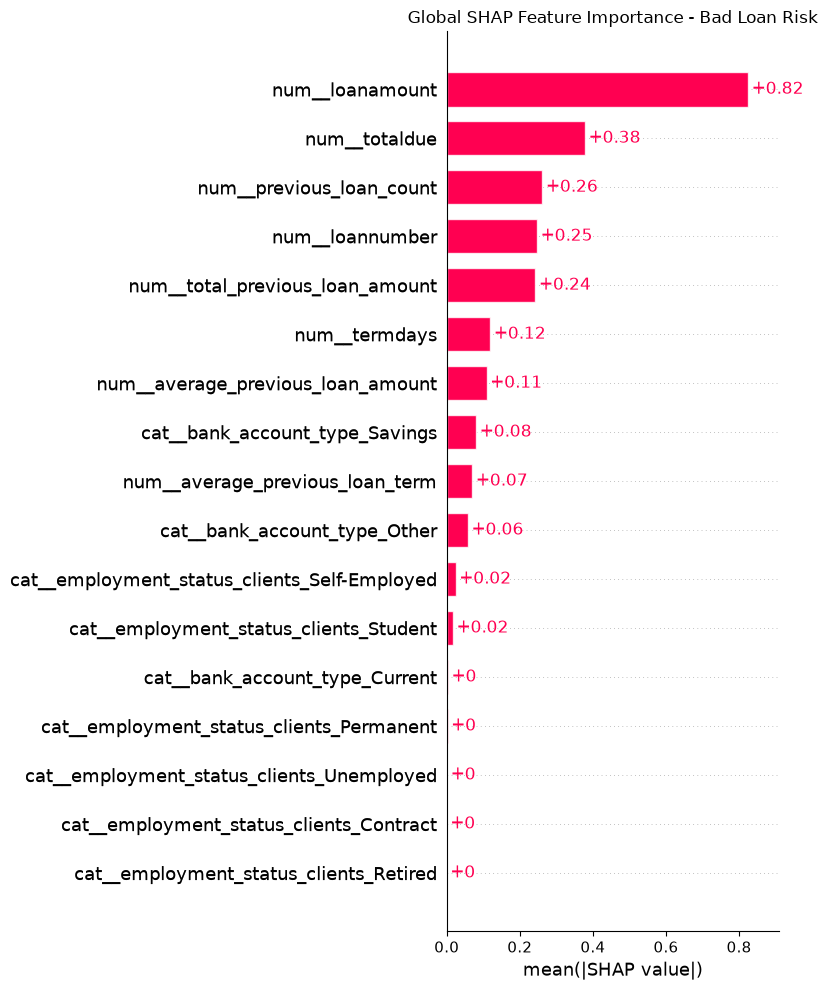

SHAP global importance plot saved!
File: C:\GroupWork\DS_research_project-maria_kisakye-\results\figures\shap_global_importance.png


In [35]:

import matplotlib.pyplot as plt
from pathlib import Path

# Create a directory for research figures
figures_dir = Path("../results/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

# Generate global SHAP feature importance plot
shap.plots.bar(
    shap_values_bad,
    max_display=17,
    show=False
)

plt.title(
    "Global SHAP Feature Importance - Bad Loan Risk"
)

plt.tight_layout()

# Save the figure
figure_path = figures_dir / "shap_global_importance.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SHAP global importance plot saved!")
print("File:", figure_path.resolve())


##### 25.8 Interpretation of Global SHAP Feature Importance

The global SHAP analysis identified loan amount as the most influential feature in the balanced Logistic Regression model, with a mean absolute SHAP value of approximately 0.82.

The second most influential feature was total amount due (0.38), followed by previous loan count (0.26), loan number (0.25), and total previous loan amount (0.24).

These findings indicate that the model relies primarily on current loan characteristics and historical borrowing information when predicting repayment outcomes.

In comparison, employment status and bank account type generally contributed less to the model's predictions.

The SHAP importance values represent the average magnitude of feature contributions to predicted Bad-loan log-odds. They do not indicate whether higher feature values increase or decrease predicted risk.

Furthermore, these explanations describe the behaviour of the trained model rather than causal relationships between borrower characteristics and repayment outcomes.

Because several financial features may be correlated, their individual importance rankings should be interpreted cautiously.

Overall, the results demonstrate that SHAP can provide useful information about which features influence the Logistic Regression baseline, supporting the explainability component of the research project.

In [36]:
# Loan amount (0.82) has the largest average contribution to the model's predicted Bad-loan log-odds. It is more than twice the importance of the second-ranked feature, total amount due.

# Total amount due (0.38) is also influential, suggesting that the model relies substantially on the financial characteristics of the current loan.

# Previous loan count (0.26), loan number (0.25), and total previous loan amount (0.24) indicate that historical borrowing behaviour contributes to the predictions.

# Employment status and bank account categories generally have smaller contributions in this fitted model.

# One important distinction: the positive numbers on this bar chart represent the magnitude of SHAP contributions, not their direction. We cannot conclude from this plot alone that larger loans increase default risk.

# Also, loan amount and total due may be strongly related. Their individual SHAP importance values should therefore be interpreted cautiously.

##### 25.9 Local SHAP Explanation

Global SHAP analysis identifies influential features across the testing dataset, while local SHAP analysis explains an individual prediction.

This section examines one correctly identified Bad loan from the testing dataset.

A SHAP waterfall plot will illustrate how the transformed feature values contribute to the model's predicted Bad-loan log-odds relative to the reference prediction.

Positive SHAP contributions increase the model's predicted Bad-loan log-odds, while negative contributions decrease them.

The explanation will help demonstrate how the model arrives at an individual credit-risk prediction.

The selected observation is used only for illustration and does not establish that the model is reliable for real-world lending decisions.

Selected test observation: 15
Actual outcome: Bad
Predicted outcome: Bad
Predicted Bad probability: 0.5435


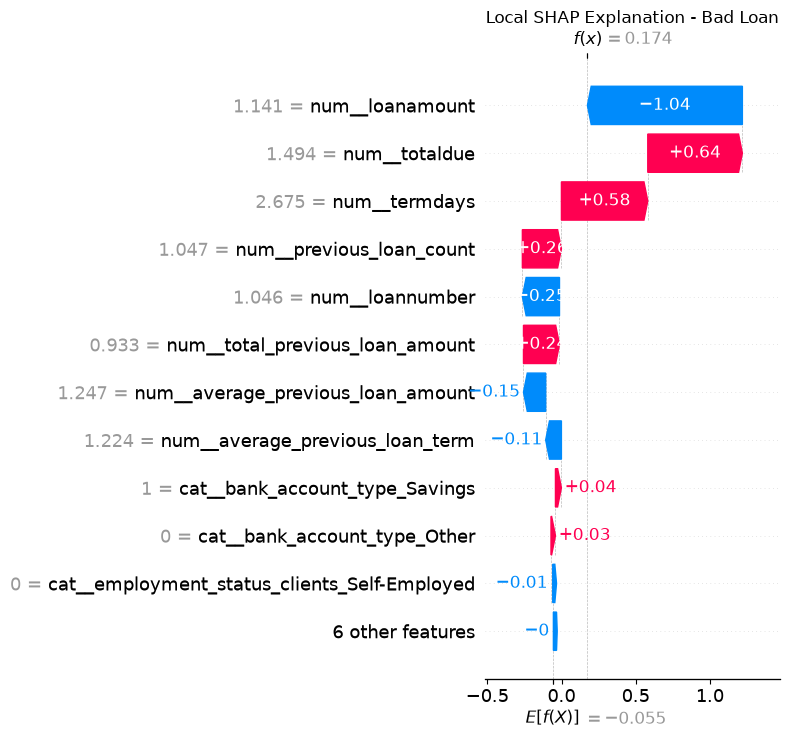


Local SHAP plot saved!
File: C:\GroupWork\DS_research_project-maria_kisakye-\results\figures\shap_local_bad_loan.png


In [37]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Find correctly identified Bad loans
correct_bad_indices = np.where(
    (np.asarray(y_test) == "Bad") &
    (np.asarray(y_pred) == "Bad")
)[0]

if len(correct_bad_indices) == 0:
    raise ValueError(
        "No correctly predicted Bad loans found."
    )

# Select the first correctly identified Bad loan
sample_index = int(correct_bad_indices[0])

print("Selected test observation:", sample_index)
print("Actual outcome:", y_test.iloc[sample_index])
print("Predicted outcome:", y_pred[sample_index])
print(
    "Predicted Bad probability:",
    round(float(y_bad_probability[sample_index]), 4)
)

# Generate SHAP waterfall plot
shap.plots.waterfall(
    shap_values_bad[sample_index],
    max_display=12,
    show=False
)

plt.title("Local SHAP Explanation - Bad Loan")
plt.tight_layout()

# Save the figure
figures_dir = Path("../results/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

local_plot_path = (
    figures_dir / "shap_local_bad_loan.png"
)

plt.savefig(
    local_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nLocal SHAP plot saved!")
print("File:", local_plot_path.resolve())


##### 25.10 Interpretation of Local SHAP Explanation

A local SHAP explanation was generated for test observation 15, which was correctly classified as a Bad loan by the balanced Logistic Regression model.

The actual repayment outcome was Bad, and the model predicted Bad with a probability of approximately 54.35%.

The SHAP waterfall plot showed that different features contributed positively and negatively to the predicted Bad-loan log-odds.

Loan amount had the largest negative contribution, approximately −1.04, indicating that its transformed value reduced the model's predicted risk relative to the reference prediction.

Total amount due and loan term had positive contributions of approximately +0.64 and +0.58, respectively, increasing the predicted Bad-loan log-odds.

Previous loan count and total previous loan amount also contributed positively, while loan number contributed negatively.

The combined feature contributions moved the prediction from a reference log-odds value of approximately −0.055 to a final value of approximately 0.174, corresponding to a predicted Bad-loan probability of 54.35%.

Although the model correctly classified this observation, the probability was close to the classification threshold of 0.5. This indicates that the prediction could change under a slightly different threshold.

The local explanation demonstrates how SHAP can make individual model predictions more interpretable. However, it does not establish causal relationships or guarantee that the model's predictions are sufficiently accurate for real-world credit decisions.